## Лабораторна робота № 6 ##

**Тема** Нейронна регресія для табличних даних у TensorFlow

**Мета роботи** Навчитися готувати реальні табличні дані без витоку інформації, порівнювати нейронні мережі з класичними моделями машинного навчання, контролювати процес навчання за допомогою валідаційної вибірки, аналізувати помилки прогнозування та зберігати всі компоненти процесу прогнозування для подальшого використання.

**Варіант** № 10 — Dropout(0.1) після кожного прихованого шару нейронної мережі.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import sklearn, joblib
import json

from tensorflow import keras
from tensorflow.keras import layers

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

SEED = 42
keras.utils.set_random_seed(SEED)

print("TensorFlow:", tf.__version__)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)
print("Matplotlib:", plt.matplotlib.__version__)
print("Joblib:", joblib.__version__)

TensorFlow: 2.21.0
NumPy: 2.5.3
Pandas: 3.0.6
Scikit-learn: 1.9.1
Matplotlib: 3.11.2
Joblib: 1.6.0


## Завантаження та перевірка даних ##

In [2]:
# Назви стовпців датасету
columns = ["mpg", "cylinders", "displacement", "horsepower",
           "weight", "acceleration", "model_year", "origin", "car_name"]

# Завантаження даних
df = pd.read_csv("auto-mpg.data", sep=r"\s+", names=columns, na_values="?")

X = df.drop(columns=["mpg", "car_name"])
y = df["mpg"].astype(np.float32)

# Перегляд перших рядків
display(df.head())

# Типи даних у стовпцях
print("\nТипи даних:")
print(df.dtypes)

# Кількість пропущених значень
print("\nКількість пропусків:")
print(df.isna().sum())

# Кількість дублікатів
print("\nКількість дублікатів:", df.duplicated().sum())

print("\nРозмір:", df.shape)


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,car_name
0,18.0,8,307.0,130.0,3504.0,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693.0,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150.0,3436.0,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150.0,3433.0,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140.0,3449.0,10.5,70,1,ford torino



Типи даних:
mpg             float64
cylinders         int64
displacement    float64
horsepower      float64
weight          float64
acceleration    float64
model_year        int64
origin            int64
car_name            str
dtype: object

Кількість пропусків:
mpg             0
cylinders       0
displacement    0
horsepower      6
weight          0
acceleration    0
model_year      0
origin          0
car_name        0
dtype: int64

Кількість дублікатів: 0

Розмір: (398, 9)


## Поділ і підготовка даних ##

In [3]:
# Спочатку відокремлюємо 15% даних для тестування
X_dev, X_test, y_dev, y_test = train_test_split(
    X, y, test_size=0.15, random_state=SEED)

# Із решти даних виділяємо validation
X_train, X_val, y_train, y_val = train_test_split(
    X_dev, y_dev, test_size=0.15/0.85, random_state=SEED)

# Перевіряємо розміри вибірок
print("Train:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)

# Перевірка індексів
print("\nПеревірка спільних індексів:")
print("Train і Validation:", len(set(X_train.index) & set(X_val.index)))
print("Train і Test:", len(set(X_train.index) & set(X_test.index)))
print("Validation і Test:", len(set(X_val.index) & set(X_test.index)))

Train: (278, 7) (278,)
Validation: (60, 7) (60,)
Test: (60, 7) (60,)

Перевірка спільних індексів:
Train і Validation: 0
Train і Test: 0
Validation і Test: 0


## Підготовка ознак через ColumnTransformer ##

In [4]:
# Числові та категоріальні ознаки
numeric_features = [
    "cylinders",
    "displacement",
    "horsepower",
    "weight",
    "acceleration",
    "model_year"
]

categorical_features = ["origin"]

# Підготовка числових ознак
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])
# Підготовка категоріальної ознаки
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])
# Об'єднання перетворень
preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

# Навчання препроцесора на навчальній вибірці
X_train_ready = preprocessor.fit_transform(X_train).astype(np.float32)
# Інші вибірки лише перетворюємо
X_val_ready = preprocessor.transform(X_val).astype(np.float32)
X_test_ready = preprocessor.transform(X_test).astype(np.float32)

# Назви підготовлених ознак
feature_names = preprocessor.get_feature_names_out()

print("Підготовлені ознаки:", feature_names)
print("\nРозмір train:", X_train_ready.shape)
print("Розмір validation:", X_val_ready.shape)
print("Розмір test:", X_test_ready.shape)

print("\nNaN у train:", np.isnan(X_train_ready).sum())
print("NaN у validation:", np.isnan(X_val_ready).sum())
print("NaN у test:", np.isnan(X_test_ready).sum())

print("Нескінченні значення у train:", np.isinf(X_train_ready).sum())
print("Нескінченні значення у validation:", np.isinf(X_val_ready).sum())
print("Нескінченні значення у test:", np.isinf(X_test_ready).sum())

Підготовлені ознаки: ['num__cylinders' 'num__displacement' 'num__horsepower' 'num__weight'
 'num__acceleration' 'num__model_year' 'cat__origin_1' 'cat__origin_2'
 'cat__origin_3']

Розмір train: (278, 9)
Розмір validation: (60, 9)
Розмір test: (60, 9)

NaN у train: 0
NaN у validation: 0
NaN у test: 0
Нескінченні значення у train: 0
Нескінченні значення у validation: 0
Нескінченні значення у test: 0


## Навчання класичних моделей ##

In [5]:
def regression_metrics(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)

    return {
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    }

# Модель, яка прогнозує середнє значення mpg
dummy_model = DummyRegressor(strategy="mean")
dummy_model.fit(X_train_ready, y_train)

# Лінійна регресія зі стандартизацією ознак
linear_model = Pipeline([
    ("scaler", StandardScaler()),
    ("regressor", LinearRegression())
])
linear_model.fit(X_train_ready, y_train)

# Прогнози на валідаційній вибірці
dummy_val_pred = dummy_model.predict(X_val_ready)
linear_val_pred = linear_model.predict(X_val_ready)

# Метрики
dummy_metrics = regression_metrics(y_val, dummy_val_pred)
linear_metrics = regression_metrics(y_val, linear_val_pred)

# Порівняльна таблиця
classical_results = pd.DataFrame([
    {"Модель": "DummyRegressor", **dummy_metrics},
    {"Модель": "LinearRegression", **linear_metrics}
])

display(classical_results)

,Модель,MAE,RMSE,R2
0,DummyRegressor,7.354940,8.611853,-0.000037
1,LinearRegression,2.901305,3.610251,0.824249


## Створення базової нейронної мережі ##

In [ ]:
keras.utils.set_random_seed(SEED)
# Створення нормалізації вхідних ознак
normalizer = layers.Normalization(axis=-1)
normalizer.adapt(X_train_ready)

# Створення базової нейромережі
model = keras.Sequential([
    layers.Input(shape=(X_train_ready.shape[1],)),
    normalizer,
    layers.Dense(32, activation="relu"),
    layers.Dense(32, activation="relu"),
    layers.Dense(1)
])

# Налаштування процесу навчання
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="mse",
    metrics=["mae"]
)

# Виведення архітектури мережі
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ normalization (Normalization)   │ (None, 9)              │            19 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,428 (5.58 KB)

 Trainable params: 1,409 (5.50 KB)

 Non-trainable params: 19 (80.00 B)

## Навчання базової нейронної мережі ##

In [7]:
# Шлях до файлу найкращої моделі
checkpoint_path = "baseline_best.keras"

# Зворотні виклики для контролю навчання
callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        mode="min",
        patience=20,
        restore_best_weights=True
    ),
    keras.callbacks.ModelCheckpoint(
        checkpoint_path,
        monitor="val_loss",
        mode="min",
        save_best_only=True
    )
]

# Навчання моделі
history = model.fit(
    X_train_ready,
    y_train.to_numpy().reshape(-1, 1),
    validation_data=(
        X_val_ready,
        y_val.to_numpy().reshape(-1, 1)
    ),
    epochs=400,
    batch_size=32,
    callbacks=callbacks,
    verbose=0
)

best_model = keras.models.load_model(checkpoint_path)

print("Фактична кількість епох:", len(history.history["loss"]))
print(
    "Найкраща епоха:",
    np.argmin(history.history["val_loss"]) + 1
)
print(
    "Найкращий val_loss:",
    min(history.history["val_loss"])
)

Фактична кількість епох: 400
Найкраща епоха: 399
Найкращий val_loss: 5.725050926208496


## Створення нейронної мережі за варіантом № 10 ##

In [8]:
keras.utils.set_random_seed(SEED)
normalizer_dropout = layers.Normalization(axis=-1)
normalizer_dropout.adapt(X_train_ready)

model_dropout = keras.Sequential([
    layers.Input(shape=(X_train_ready.shape[1],)),
    normalizer_dropout,
    layers.Dense(32, activation="relu"),
    layers.Dropout(0.1),
    layers.Dense(32, activation="relu"),
    layers.Dropout(0.1),
    layers.Dense(1)
])

model_dropout.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="mse",
    metrics=["mae"]
)

model_dropout.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ normalization_1 (Normalization) │ (None, 9)              │            19 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 32)             │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,428 (5.58 KB)

 Trainable params: 1,409 (5.50 KB)

 Non-trainable params: 19 (80.00 B)

## Навчання мережі з Dropout ##

In [9]:
checkpoint_path_dropout = "dropout_best.keras"

callbacks_dropout = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        mode="min",
        patience=20,
        restore_best_weights=True
    ),
    keras.callbacks.ModelCheckpoint(
        checkpoint_path_dropout,
        monitor="val_loss",
        mode="min",
        save_best_only=True
    )
]

history_dropout = model_dropout.fit(
    X_train_ready,
    y_train.to_numpy().reshape(-1, 1),
    validation_data=(
        X_val_ready,
        y_val.to_numpy().reshape(-1, 1)
    ),
    epochs=400,
    batch_size=32,
    callbacks=callbacks_dropout,
    verbose=0
)

best_model_dropout = keras.models.load_model(checkpoint_path_dropout)

print("Фактична кількість епох:", len(history_dropout.history["loss"]))
print(
    "Найкраща епоха:",
    np.argmin(history_dropout.history["val_loss"]) + 1
)
print("Найкращий val_loss:", min(history_dropout.history["val_loss"]))

Фактична кількість епох: 135
Найкраща епоха: 115
Найкращий val_loss: 7.342414379119873


## Графік навчання мережі з Dropout ##

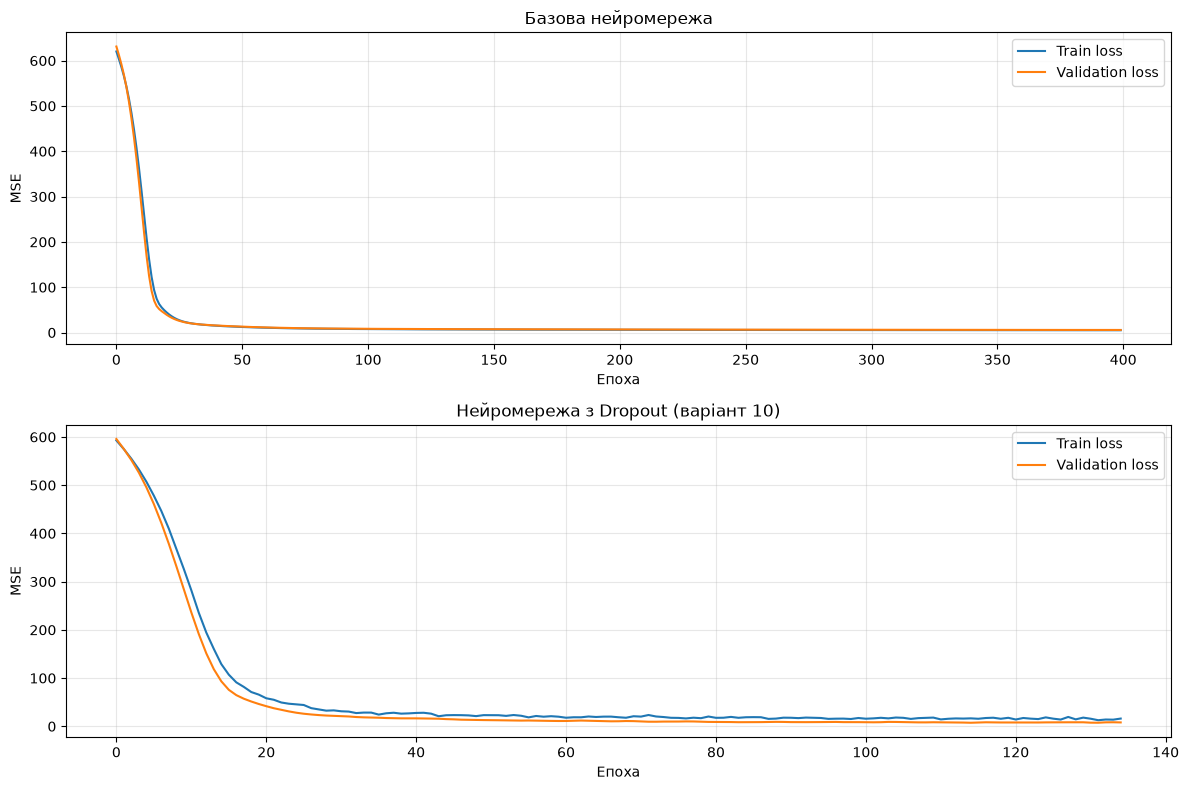

In [10]:
plt.figure(figsize=(12, 8))

# Базова нейромережа
plt.subplot(2, 1, 1)
plt.plot(history.history["loss"], label="Train loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.title("Базова нейромережа")
plt.xlabel("Епоха")
plt.ylabel("MSE")
plt.legend()
plt.grid(alpha=0.3)

# Нейромережа з Dropout
plt.subplot(2, 1, 2)
plt.plot(history_dropout.history["loss"], label="Train loss")
plt.plot(history_dropout.history["val_loss"], label="Validation loss")
plt.title("Нейромережа з Dropout (варіант 10)")
plt.xlabel("Епоха")
plt.ylabel("MSE")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## Порівняння моделей за validation RMSE ##

In [11]:
# Прогнози на validation
dummy_val_pred = dummy_model.predict(X_val_ready)
linear_val_pred = linear_model.predict(X_val_ready)

baseline_val_pred = best_model.predict(X_val_ready, verbose=0).ravel()
dropout_val_pred = best_model_dropout.predict(X_val_ready, verbose=0).ravel()

# Таблиця метрик
validation_results = pd.DataFrame([
    {
        "Модель": "DummyRegressor",
        **regression_metrics(y_val, dummy_val_pred)
    },
    {
        "Модель": "LinearRegression",
        **regression_metrics(y_val, linear_val_pred)
    },
    {
        "Модель": "Baseline Neural Network",
        **regression_metrics(y_val, baseline_val_pred)
    },
    {
        "Модель": "Neural Network with Dropout",
        **regression_metrics(y_val, dropout_val_pred)
    }
])

display(
    validation_results.sort_values("RMSE").reset_index(drop=True)
)

,Модель,MAE,RMSE,R2
0,Baseline Neural Network,1.810649,2.392708,0.922803
1,Neural Network with Dropout,2.026971,2.709689,0.900994
2,LinearRegression,2.901305,3.610251,0.824249
3,DummyRegressor,7.354940,8.611853,-0.000037


## Визначення найкращих моделей ##

In [12]:
# Найкраща модель загалом
best_overall_name = validation_results.loc[
    validation_results["RMSE"].idxmin(), "Модель"
]

# Найкраща нейромережа
neural_results = validation_results[
    validation_results["Модель"].isin([
        "Baseline Neural Network",
        "Neural Network with Dropout"
    ])
]

best_neural_name = neural_results.loc[
    neural_results["RMSE"].idxmin(), "Модель"
]

print("Найкраща модель загалом:", best_overall_name)
print("Найкраща нейромережа:", best_neural_name)

Найкраща модель загалом: Baseline Neural Network
Найкраща нейромережа: Baseline Neural Network


## Оцінювання моделей на тестових даних ##

In [13]:

# Прогнози на тестових даних
dummy_test_pred = dummy_model.predict(X_test_ready)
linear_test_pred = linear_model.predict(X_test_ready)

baseline_test_pred = best_model.predict(
    X_test_ready, verbose=0
).ravel()

dropout_test_pred = best_model_dropout.predict(
    X_test_ready, verbose=0
).ravel()

# Таблиця тестових результатів
test_results = pd.DataFrame([
    {
        "Модель": "DummyRegressor",
        **regression_metrics(y_test, dummy_test_pred)
    },
    {
        "Модель": "LinearRegression",
        **regression_metrics(y_test, linear_test_pred)
    },
    {
        "Модель": "Baseline Neural Network",
        **regression_metrics(y_test, baseline_test_pred)
    },
    {
        "Модель": "Neural Network with Dropout",
        **regression_metrics(y_test, dropout_test_pred)
    }
])

display(test_results.sort_values("RMSE").reset_index(drop=True))

,Модель,MAE,RMSE,R2
0,Baseline Neural Network,1.707615,2.283649,0.906945
1,Neural Network with Dropout,1.898248,2.360086,0.900611
2,LinearRegression,2.402458,3.057970,0.833142
3,DummyRegressor,6.067758,7.488162,-0.000532


## Таблиця має містити: назву, validation RMSE, test MAE, test RMSE, test R²; для мереж також кількість епох і найкращу епоху.  ##

In [14]:

# Об'єднуємо валідаційні та тестові результати
final_results = validation_results[["Модель", "RMSE"]].rename(
    columns={"RMSE": "Validation RMSE"}
)

final_results = final_results.merge(
    test_results[["Модель", "MAE", "RMSE", "R2"]],
    on="Модель"
)

final_results = final_results.rename(columns={
    "MAE": "Test MAE",
    "RMSE": "Test RMSE",
    "R2": "Test R2"
})

# Додаємо кількість епох і найкращу епоху
final_results["Кількість епох"] = None
final_results["Найкраща епоха"] = None

final_results.loc[
    final_results["Модель"] == "Baseline Neural Network",
    "Кількість епох"
] = len(history.history["loss"])

final_results.loc[
    final_results["Модель"] == "Baseline Neural Network",
    "Найкраща епоха"
] = np.argmin(history.history["val_loss"]) + 1

final_results.loc[
    final_results["Модель"] == "Neural Network with Dropout",
    "Кількість епох"
] = len(history_dropout.history["loss"])

final_results.loc[
    final_results["Модель"] == "Neural Network with Dropout",
    "Найкраща епоха"
] = np.argmin(history_dropout.history["val_loss"]) + 1

# Сортуємо за validation RMSE
display(
    final_results.sort_values("Validation RMSE").reset_index(drop=True)
)



,Модель,Validation RMSE,Test MAE,Test RMSE,Test R2,Кількість епох,Найкраща епоха
0,Baseline Neural Network,2.392708,1.707615,2.283649,0.906945,400,399
1,Neural Network with Dropout,2.709689,1.898248,2.360086,0.900611,135,115
2,LinearRegression,3.610251,2.402458,3.057970,0.833142,None,None
3,DummyRegressor,8.611853,6.067758,7.488162,-0.000532,None,None


## Графіки прогнозів і помилок ##

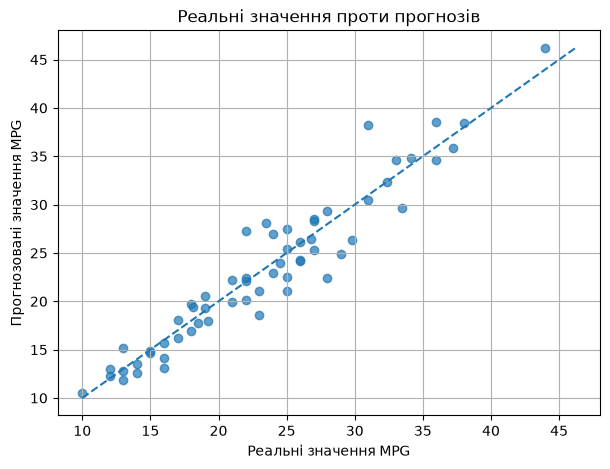

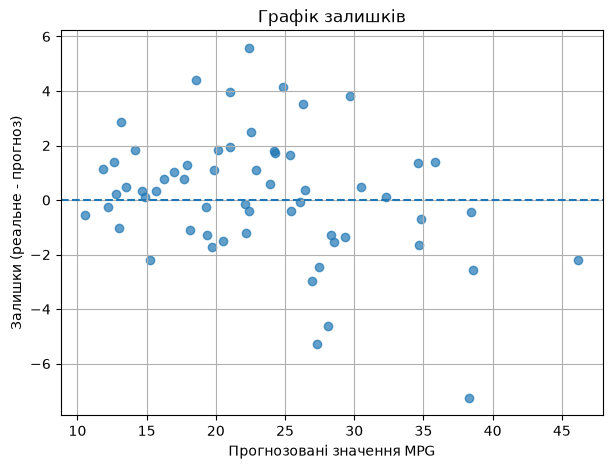

In [ ]:
# Вибираємо нейромережу, яка показала найкращий Validation RMSE
if best_neural_name == "Baseline Neural Network":
    selected_nn = best_model
else:
    selected_nn = best_model_dropout

# Прогнози на тестових даних
y_pred = selected_nn.predict(X_test_ready, verbose=0).ravel()
y_true = y_test.to_numpy()

# Графік реальних значень і прогнозів
plt.figure(figsize=(7, 5))
plt.scatter(y_true, y_pred, alpha=0.7)

min_value = min(y_true.min(), y_pred.min())
max_value = max(y_true.max(), y_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel("Реальні значення MPG")
plt.ylabel("Прогнозовані значення MPG")
plt.title("Реальні значення проти прогнозів")
plt.grid(True)
plt.show()

# Графік залишків
residuals = y_true - y_pred

plt.figure(figsize=(7, 5))
plt.scatter(y_pred, residuals, alpha=0.7)
plt.axhline(y=0, linestyle="--")

plt.xlabel("Прогнозовані значення MPG")
plt.ylabel("Залишки (реальне - прогноз)")
plt.title("Графік залишків")
plt.grid(True)
plt.show()

## Аналіз п’яти найбільших помилок ##

In [16]:
# Формуємо таблицю з реальними значеннями та прогнозами
error_analysis = X_test.copy()

error_analysis["Реальне MPG"] = y_true
error_analysis["Прогноз MPG"] = y_pred
error_analysis["Абсолютна помилка"] = np.abs(y_true - y_pred)

# Виводимо 5 автомобілів із найбільшими помилками
largest_errors = error_analysis.sort_values(
    "Абсолютна помилка", ascending=False
).head(5)

display(largest_errors)

,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,Реальне MPG,Прогноз MPG,Абсолютна помилка
377,4,91.0,68.0,1970.0,17.6,82,3,31.0,38.261814,7.261814
30,4,140.0,90.0,2264.0,15.5,71,1,28.0,22.422840,5.577160
389,6,232.0,112.0,2835.0,14.7,82,1,22.0,27.293568,5.293568
341,6,173.0,110.0,2725.0,12.6,81,1,23.5,28.129175,4.629175
298,8,350.0,125.0,3900.0,17.4,79,1,23.0,18.582060,4.417940



### Аналіз п'яти найбільших помилок

Найбільші помилки можуть виникати через те, що модель не враховує всі характеристики автомобіля, які впливають на витрату пального. На результат можуть впливати особливості двигуна, вага автомобіля, рік випуску та інші характеристики.

Якщо автомобілі з найбільшими помилками мають нетипове поєднання характеристик, модель може недостатньо точно оцінювати їхню паливну ефективність. Також помилки можуть бути пов'язані з обмеженою кількістю навчальних прикладів із подібними характеристиками.

Ці автомобілі залишаються в тестовій вибірці, оскільки їх не потрібно видаляти лише через великі помилки прогнозування.


## Збереження найкращої нейромережі ##

In [17]:

# Зберігаємо найкращу нейромережу
selected_nn.save("lab6_model.keras")

# Зберігаємо препроцесор
joblib.dump(preprocessor, "preprocessor.joblib")

print("Нейромережу збережено: lab6_model.keras")
print("Препроцесор збережено: preprocessor.joblib")

Нейромережу збережено: lab6_model.keras
Препроцесор збережено: preprocessor.joblib
